In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import torch
import random
import time

# Add the current directory to the path to ensure the notebook can find the local module
if os.path.abspath('.') not in sys.path:
    sys.path.append(os.path.abspath('.'))

from random_besov import FastWaveletBatchGenerator
from random_besov_ds import FastWaveletBatchGenerator_ds
from matplotlib.lines import Line2D

In [2]:
###### Sampling Utilities
def sample_unit_ball(n, d):
    z = np.random.normal(size=(n, d))
    z /= np.linalg.norm(z, axis=1, keepdims=True)
    r = np.random.uniform(size=(n, 1)) ** (1 / d)
    return r * z


def sample_stiefel(d, p):
    if p > d:
        raise ValueError("p must be <= d")

    Z = np.random.normal(size=(d, p))
    Q, R = np.linalg.qr(Z)

    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1
    Q *= signs
    return Q


def random_project(X, p):
    d = X.shape[1]
    U = sample_stiefel(d, p)
    X_projected = (np.matmul(X, U) + 1) / 2
    return X_projected

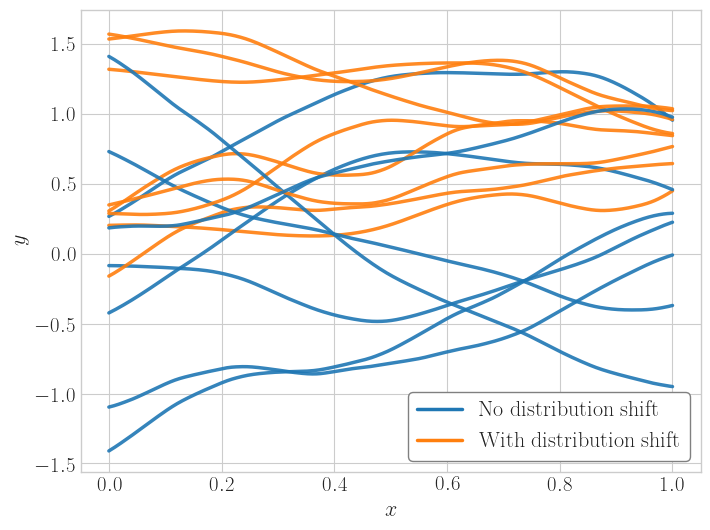

In [13]:
X_list = []
num_functions = 8
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 

params = {'d': 1, 'alpha': 4, 'J': 10, 'C0': 2.0, 'seed': 42*1}
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()

params = {'d': 1, 'alpha': 4, 'J': 10, 'C0': 2.0, 'seed': 42*2}
random_besov_generator_ds = FastWaveletBatchGenerator_ds(wavelet='db6', cascade_level=8)
Y_list_ds = random_besov_generator_ds.generate_batch(X_list, params)
random_besov_generator_ds.cleanup()


# Plot the results
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 6))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    y_coords = Y_list[i]
    ax.plot(x_coords, y_coords, color='C0', alpha=0.9, lw=2.5)
    y_coords_ds = Y_list_ds[i]
    ax.plot(x_coords, y_coords_ds, color='C1', alpha=0.9, lw=2.5)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
legend_handles = [
    Line2D([0], [0], color='C0', lw=2.5, label='No distribution shift'),
    Line2D([0], [0], color='C1', lw=2.5, label='With distribution shift'),
]
legend = ax.legend(
    handles=legend_handles,
    fontsize=16,
    frameon=True,
    fancybox=True,
    framealpha=1.0
)

legend.get_frame().set_edgecolor('grey')
legend.get_frame().set_linewidth(1.0)
legend.get_frame().set_facecolor('white')
plt.tick_params(axis='both', which='major', labelsize=15)
plt.xlabel('$x$', fontsize=16)
plt.ylabel('$y$', fontsize=16)

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Times New Roman",
    "text.latex.preamble": r"\usepackage{lmodern}\usepackage[T1]{fontenc}"
})

ax.grid(True)
plt.savefig("random_besov_ds_alpha=4.pdf", bbox_inches='tight')
plt.show()

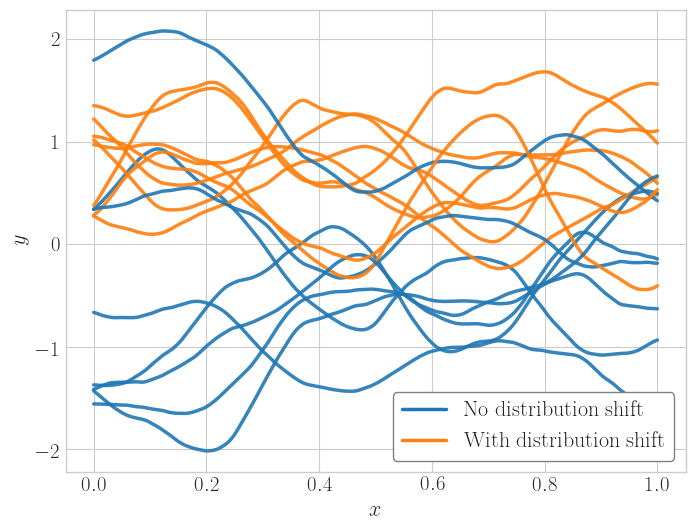

In [12]:
X_list = []
num_functions = 8
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 

params = {'d': 1, 'alpha': 2, 'J': 10, 'C0': 2.0, 'seed': 42*3}
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()

params = {'d': 1, 'alpha': 2, 'J': 10, 'C0': 2.0, 'seed': 42*4}
random_besov_generator_ds = FastWaveletBatchGenerator_ds(wavelet='db6', cascade_level=8)
Y_list_ds = random_besov_generator_ds.generate_batch(X_list, params)
random_besov_generator_ds.cleanup()


# Plot the results
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(8, 6))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    y_coords = Y_list[i]
    ax.plot(x_coords, y_coords, color='C0', alpha=0.9, lw=2.5)
    y_coords_ds = Y_list_ds[i]
    ax.plot(x_coords, y_coords_ds, color='C1', alpha=0.9, lw=2.5)

ax.set_xlabel('x')
ax.set_ylabel('y')
legend_handles = [
    Line2D([0], [0], color='C0', lw=2.5, label='No distribution shift'),
    Line2D([0], [0], color='C1', lw=2.5, label='With distribution shift'),
]
legend = ax.legend(
    handles=legend_handles,
    loc='lower right',
    fontsize=16,
    frameon=True,
    fancybox=True,
    framealpha=1.0
)

legend.get_frame().set_edgecolor('grey')
legend.get_frame().set_linewidth(1.0)
legend.get_frame().set_facecolor('white')
plt.tick_params(axis='both', which='major', labelsize=15)
plt.xlabel('$x$', fontsize=16)
plt.ylabel('$y$', fontsize=16)

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Times New Roman",
    "text.latex.preamble": r"\usepackage{lmodern}\usepackage[T1]{fontenc}"
})

ax.grid(True)
plt.savefig("random_besov_ds_alpha=2.pdf", bbox_inches='tight')
plt.show()